In [1]:
import datetime as dt
import pandas as pd
from EDA import *
from claude.claude_map import *

CHANNELS = [
    "temperature_2m",
    "shortwave_radiation",
    "direct_radiation",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "cloud_cover",
]

START_DATE = dt.datetime(2025, 7, 1, 0, 0)
END_DATE = dt.datetime(2026, 8, 31, 23, 0)

PV_CSV = '../Datasets/PV/PV_DTU.csv'
NWP_CSV = '../Datasets/NWP/ECMWF_forecast_DTU.csv'
REANALYSIS_CSV = '../Datasets/Reanalysis/ECMWF_reanalysis_DTU.csv'

# Load Datasets
nwp = pd.read_csv(NWP_CSV, parse_dates=["init_time_utc"])
reanalysis = pd.read_csv(REANALYSIS_CSV, parse_dates=["init_time_utc"])
pv = pd.read_csv(PV_CSV, parse_dates=["time"])

# Transform step + init_time format into hourly records
step = pd.to_timedelta(nwp["step"], unit="h")
nwp['time'] = (nwp['init_time_utc'] + step).dt.floor("h")
nwp = nwp.drop(columns=['step','init_time_utc'])

step = pd.to_timedelta(reanalysis["step"], unit="h")
reanalysis['time'] = (reanalysis['init_time_utc'] + step).dt.floor("h")
reanalysis = reanalysis.drop(columns=['step','init_time_utc'])

# Filter to time of interest
start = nwp['time'] >= START_DATE
end = nwp['time'] <= END_DATE
nwp = nwp.loc[start & end]

start = reanalysis['time'] >= START_DATE
end = reanalysis['time'] <= END_DATE
reanalysis = reanalysis.loc[start & end]

start = pv['time'] >= START_DATE
end = pv['time'] <= END_DATE
pv = pv.loc[start & end]

nwp = nwp.drop(columns="is_day")

## Missing values

### NWP

* The number of missing values is the same for all locations
* Certain weather variables have more missing values than other ones 
* `shortwave_radiation` and `direct_radiation` are the ones with more missing values (5% compared to ~1%)
* `shortwave_radiation` and `direct_radiation` missing values gaps often last only one hour
* On the 05/08/2025, 06/08/2025, 08/08/2025, 09/08/2025 no results were generated from the ECWMF midnight model run

In [ ]:
temp = nwp.copy()
temp["loc"] = list(zip(temp["latitude"], temp["longitude"]))
value_cols = [c for c in temp.columns if c not in ["time", "latitude", "longitude", "loc"]]

miss_count = temp.groupby(["latitude", "longitude"])[value_cols].apply(lambda g: g.isna().sum())
print(miss_count)

In [ ]:
# Focusing on only one set of coordinates since it does not change
temp = nwp.copy()
latitude = temp['latitude'] == 55.67
longitude = temp['longitude'] == 12.08
temp = temp.loc[latitude & longitude]
temp = temp.drop(columns=["latitude", "longitude"])

# Force hour periodicity 
temp = temp.set_index(['time']).sort_index()
full_idx = pd.date_range(START_DATE, END_DATE, freq="h", name="time")
temp = temp.reindex(full_idx)

print(f"Summary missing data:", temp.isna().sum(), temp.isna().mean() * 100)

In [ ]:
plot_missing_values(temp)

In [ ]:
for c in CHANNELS:
    gaps = get_missing_value_gaps(temp[c]).sort_values("length_h", ascending=False)
    print(c + "\n")
    print("Number of gaps:", len(gaps))
    print(f"\nLongest gap:",gaps.head())
    print("\n")

    dist = gaps["length_h"].value_counts().sort_index()
    print(dist)
    print("\n")

### Solar Power

*  a good part of august 2025 is not recorded

In [ ]:
# Force hour periodicity 
temp = pv.copy()
temp = temp.set_index(['time']).sort_index()
full_idx = pd.date_range(START_DATE, END_DATE, freq="h", name="time")
temp = temp.reindex(full_idx)

print(f"Summary missing data:", temp.isna().sum(), temp.isna().mean() * 100)

In [ ]:
plot_missing_values(temp)

In [ ]:
gaps = get_missing_value_gaps(temp["solar_power"]).sort_values("length_h", ascending=False)
print("Solar Power\n")
print("Number of gaps:", len(gaps))
print(f"\nLongest gap:",gaps.head())
print("\n")

dist = gaps["length_h"].value_counts().sort_index()
print(dist)
print("\n")

## NWP Grid Variation

* 

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

temp = nwp.copy()
temp["loc"] = list(zip(temp["latitude"], temp["longitude"]))

atol = {v: 0 for v in CHANNELS}

def to_wide(df, var):
    return df.pivot_table(index="time", columns="loc", values=var, aggfunc="first")

def change_summary(wide):
    d = wide.diff()
    return pd.DataFrame({
        "pct_hours_changed": (d.abs() > 0).sum() / d.notna().sum() * 100,
        "n_unique_values": wide.nunique(),
        "std": wide.std(),
        "mean_abs_hourly_change": d.abs().mean(),
    })

def agreement_matrix(wide, atol=0.0):
    cols = wide.columns
    arr = wide.to_numpy()
    out = np.full((len(cols), len(cols)), np.nan)
    for i in range(len(cols)):
        for j in range(i, len(cols)):
            valid = ~np.isnan(arr[:, i]) & ~np.isnan(arr[:, j])
            if valid.any():
                same = np.abs(arr[valid, i] - arr[valid, j]) <= atol
                out[i, j] = out[j, i] = same.mean() * 100
    return pd.DataFrame(out, index=cols, columns=cols)

def top_pairs(agree):
    agree = agree.rename_axis(index="loc_a", columns="loc_b")
    mask = np.triu(np.ones(agree.shape), k=1).astype(bool)
    p = agree.where(mask).stack().rename("pct_agree").reset_index()
    return p.sort_values("pct_agree", ascending=False)

results = {}

for var in CHANNELS:
    wide = to_wide(temp, var)
    agree = agreement_matrix(wide, atol=atol[var])
    results[var] = {
        "wide": wide,
        "change": change_summary(wide),
        "agree": agree,
        "pairs": top_pairs(agree),
    }

n = len(CHANNELS)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 7 * nrows), squeeze=False)

for ax, var in zip(axes.ravel(), CHANNELS):
    mask = np.triu(np.ones_like(results[var]["agree"], dtype=bool))
    sns.heatmap(results[var]["agree"], cmap="viridis", vmin=0, vmax=100,
                cbar_kws={"label": "% agreement"}, annot=True, annot_kws={"fontsize":8}, fmt='.0f', mask=mask, ax=ax)
    ax.set_title(f"{var} (atol={atol[var]})")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print(results[var]["change"].round(3))
print(results[var]["pairs"].head(10))   # most similar pairs
print(results[var]["pairs"].tail(10))   # least similar pairs

In [ ]:
fig = plot_weather_map(
    nwp,
    times=["2025-08-11 17:00"],
    variables=CHANNELS,
    mode="value",                               
)

## How does Solar Power vary with NWP variables?

In [ ]:
df = pd.merge(pv, nwp, how="outer")
temp = df.copy()
# Focusing on one coordinate pair for simplicity
latitude = temp['latitude'] == 55.67
longitude = temp['longitude'] == 12.08
temp = temp.loc[latitude & longitude]
temp = temp.drop(columns=["latitude", "longitude"])


In [ ]:
for c in CHANNELS:
    plot_nwp_vs_pv_data(temp, c)

In [ ]:
for c in CHANNELS:
    box_plot(temp, c)

box_plot(temp, 'solar_power')

In [ ]:
for c in CHANNELS:
    scatter_plot(temp, c)

In [ ]:
for c in CHANNELS:
    z_score(df, c)

z_score(df, 'solar_power')

In [ ]:
temp = df.copy()
latitude = temp['latitude'] == 55.67
longitude = temp['longitude'] == 12.08
temp = temp.loc[latitude & longitude]
temp = temp.drop(columns=["latitude", "longitude"])
correlation_heatmap(temp)

## NWP Vs Reanalysis

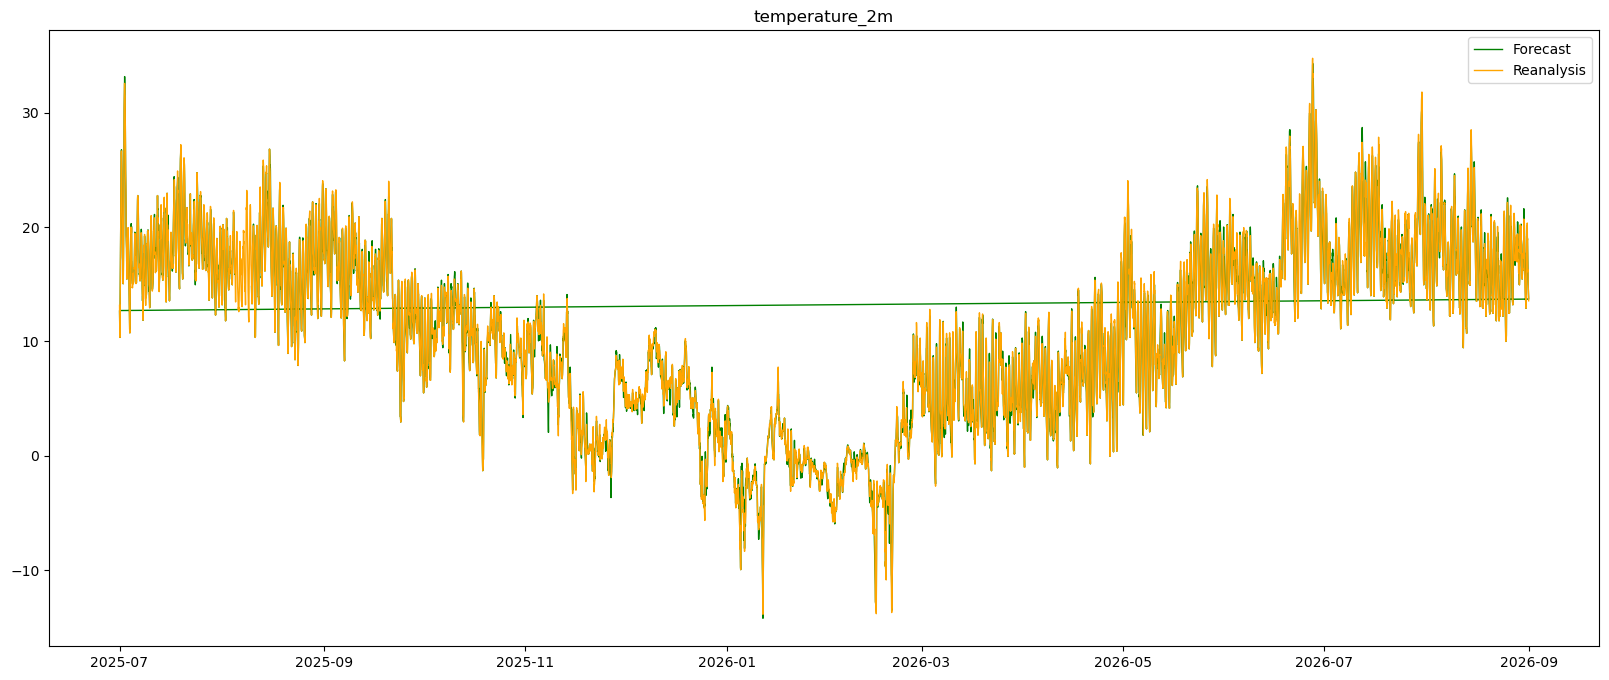

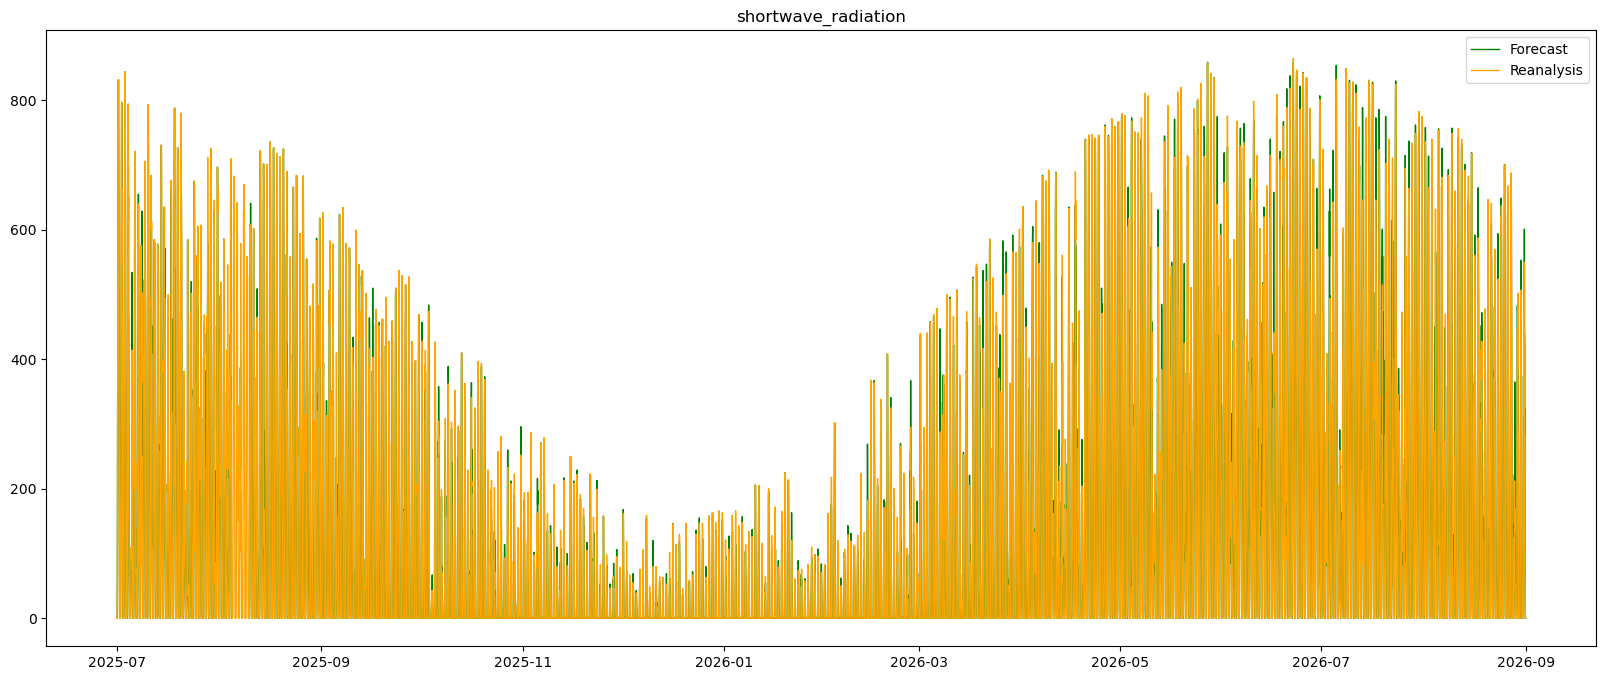

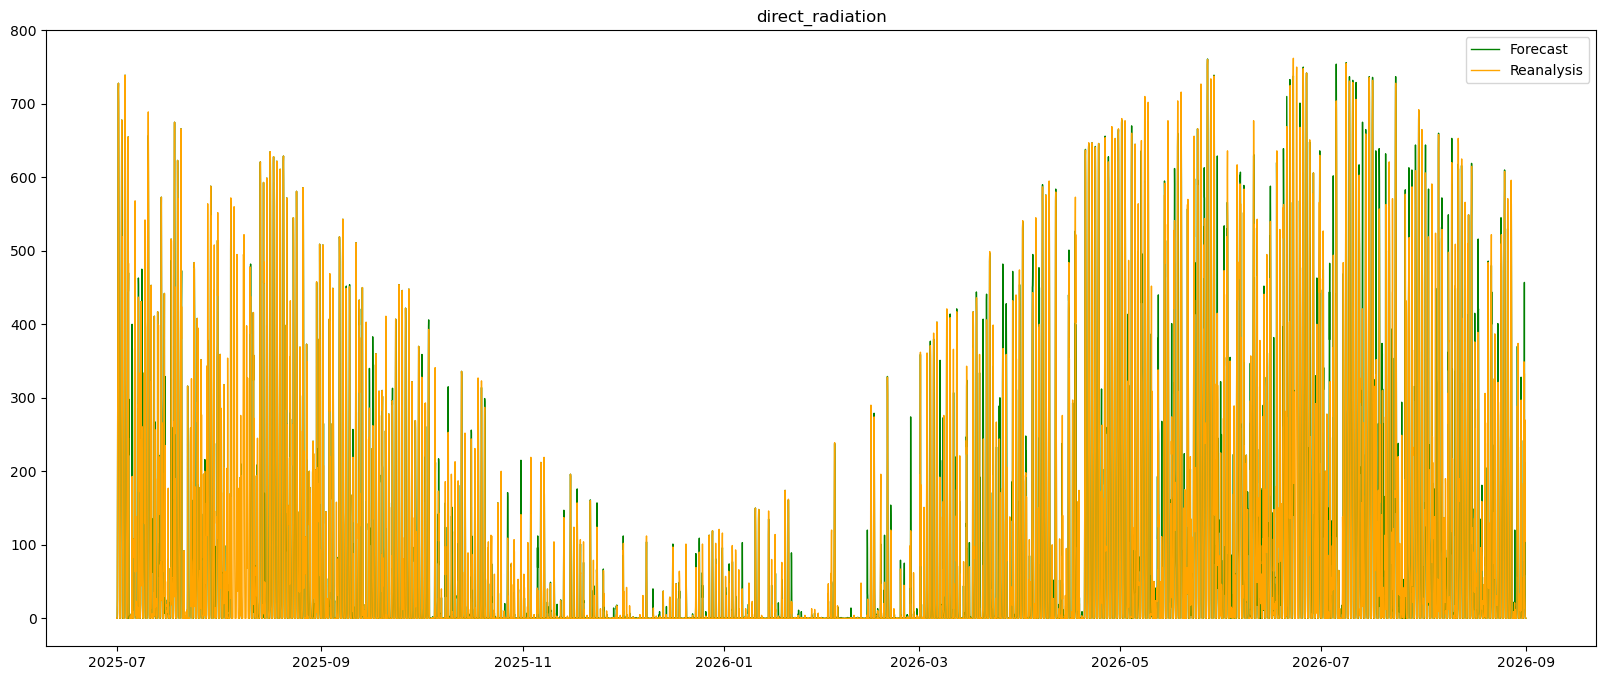

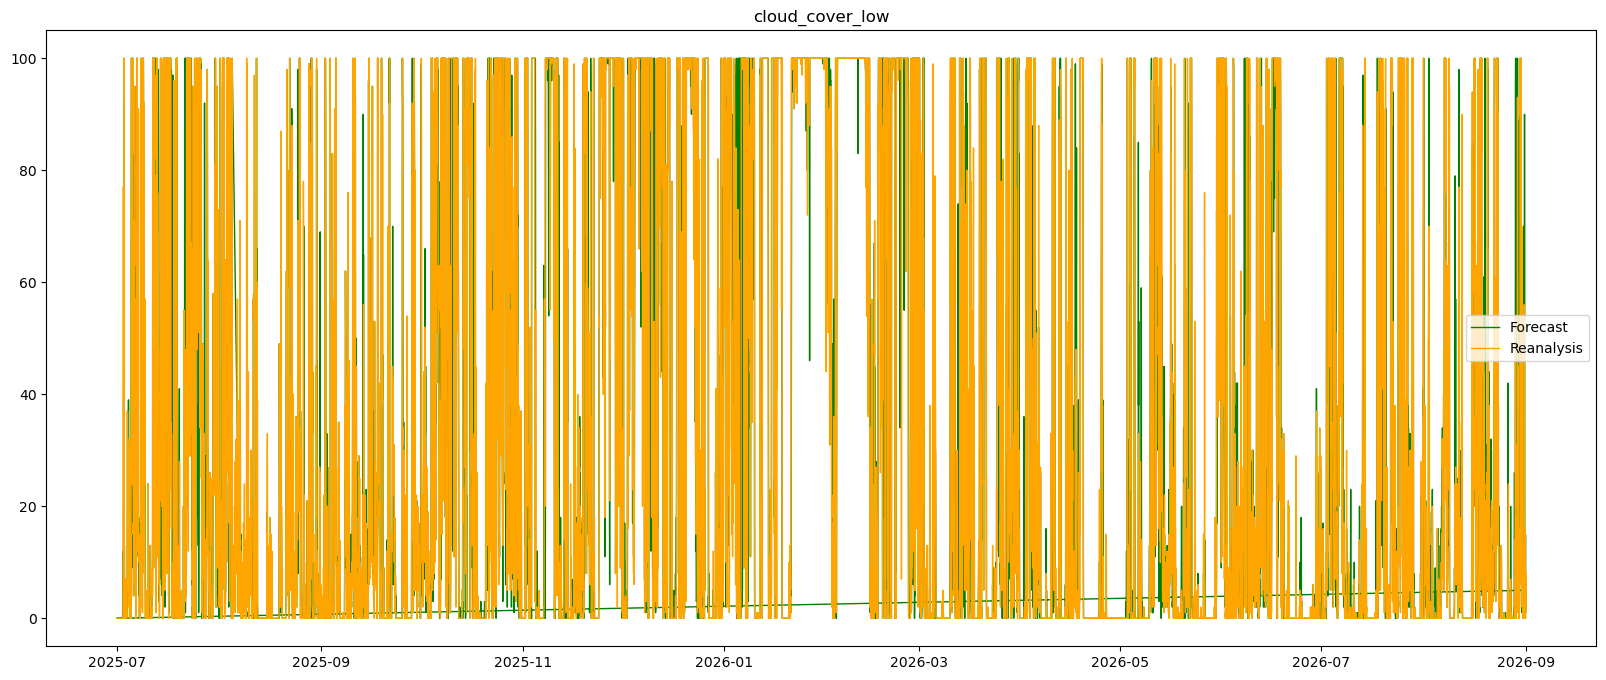

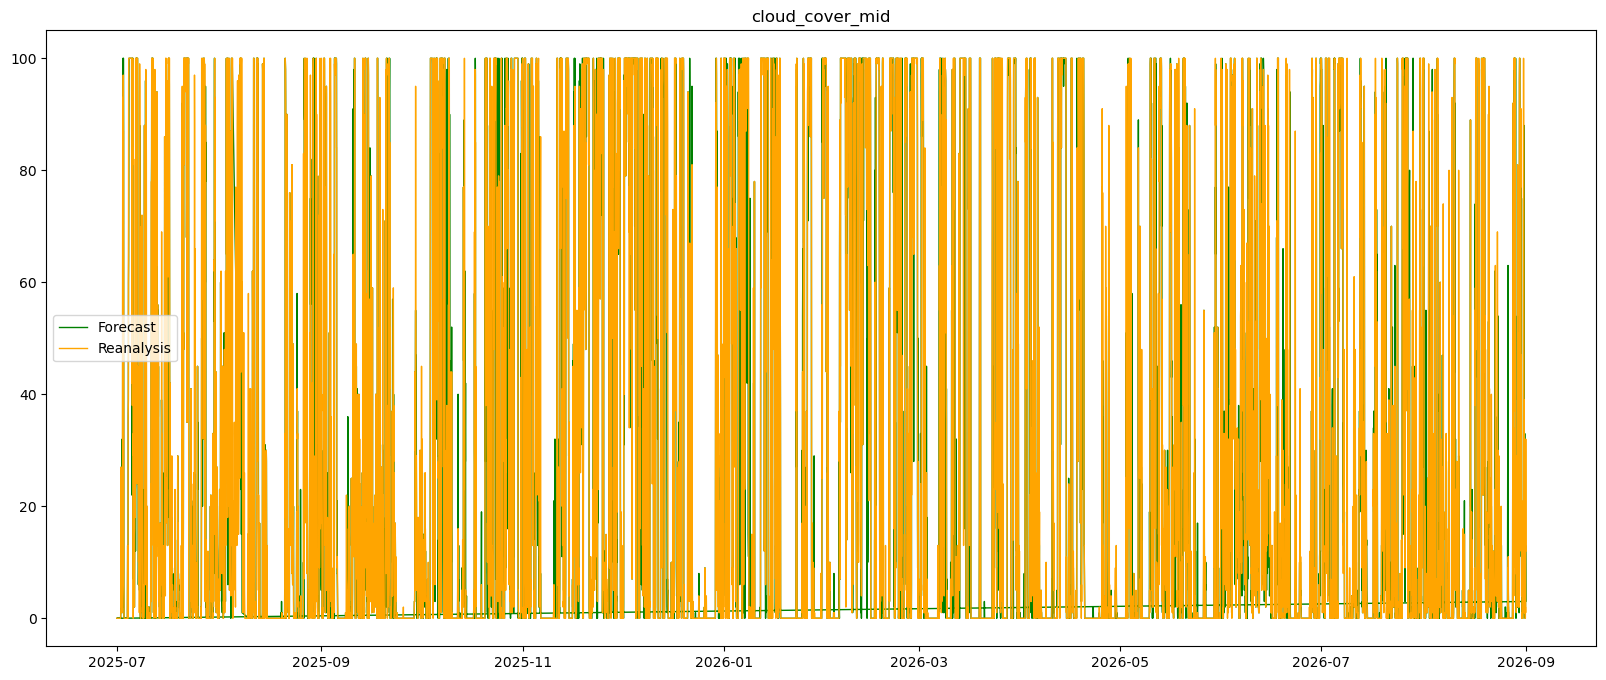

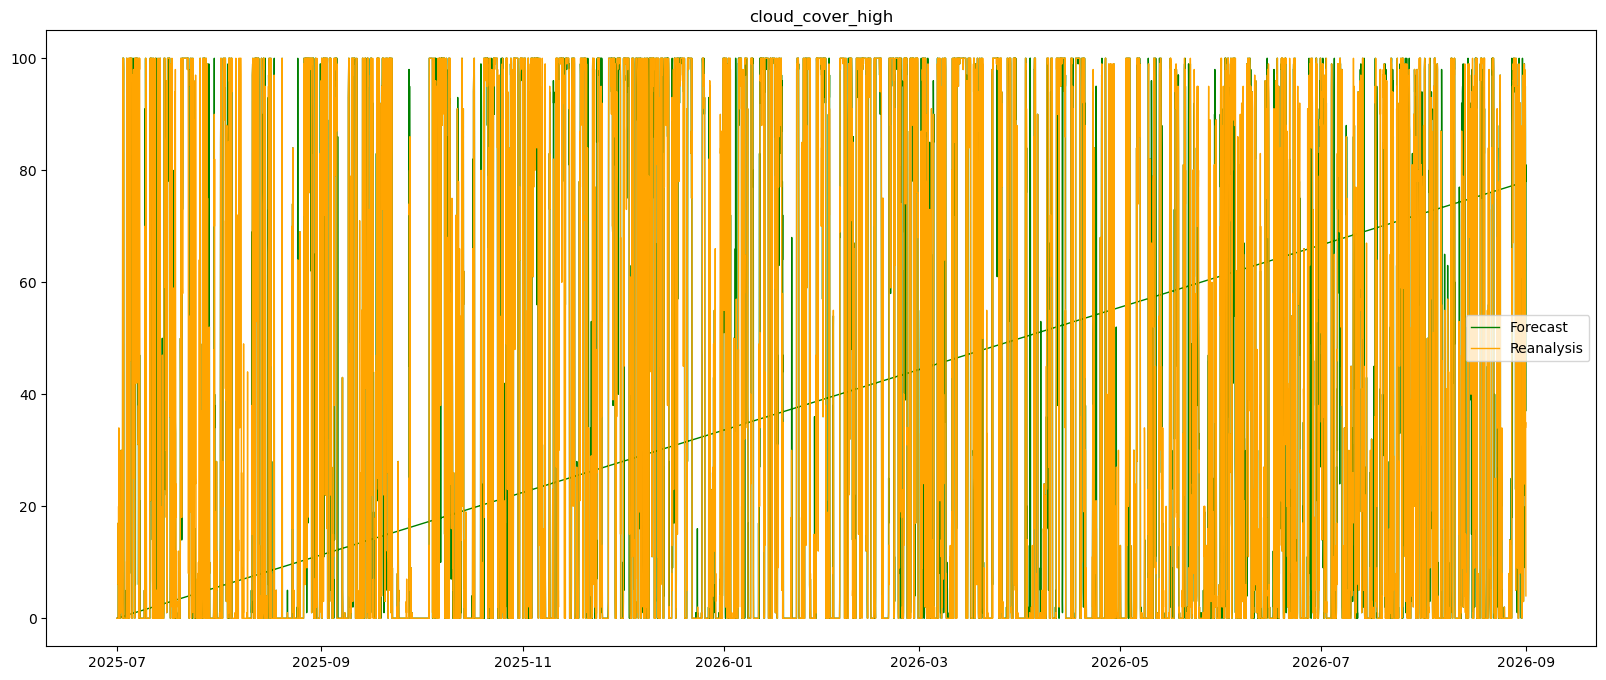

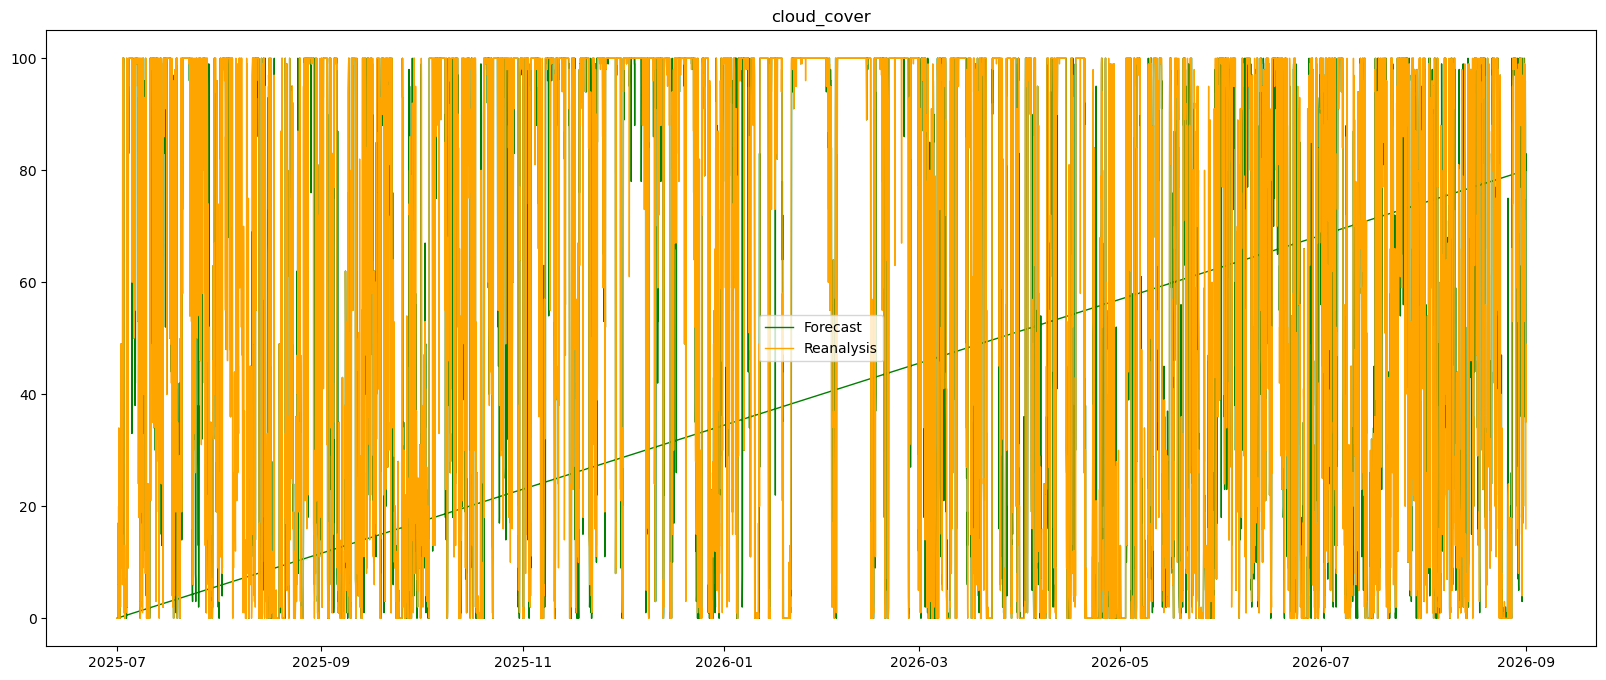

In [2]:
temp_nwp = nwp.copy()
latitude = temp_nwp['latitude'] == 55.67
longitude = temp_nwp['longitude'] == 12.08
temp_nwp = temp_nwp.loc[latitude & longitude]
temp_nwp = temp_nwp.drop(columns=["latitude", "longitude"])

temp_reanalysis = reanalysis.copy()
latitude = temp_reanalysis['latitude'] == 55.67
longitude = temp_reanalysis['longitude'] == 12.08
temp_reanalysis = temp_reanalysis.loc[latitude & longitude]
temp_reanalysis = temp_reanalysis.drop(columns=["latitude", "longitude"])

for c in CHANNELS:
    plot_nwp_vs_reanalysis_data(temp_nwp, temp_reanalysis, c)